# A standalone fix: from pseudoranges to a position

This notebook takes RINEX observations and broadcast ephemerides and turns them into a
position, epoch by epoch, with nothing but the satellites' own messages: satellite
positions and clocks from the ephemeris, atmospheric delays from the broadcast models,
and a weighted least-squares solution of position and receiver clock.

It runs on three hours of the IGS station USUD (Usuda, Japan) on 2021-12-26 when the
environment variable `PYRX_CAPTURES` points at the recordings directory (see
`../README.md`), and otherwise on an hour of synthetic epochs generated from the package's
own models. The committed outputs are from the station.

The fundamentals behind it: [The measurements](../../docs/fundamentals/07-measurements.md)
and [A standalone fix](../../docs/fundamentals/08-standalone-fix.md).

In [1]:
import warnings

import hatanaka
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from support import (
    PVT_SPAN,
    PVT_WINDOW,
    USUD_MARKER,
    data_source,
    enu,
    figure,
    rnx2rtkp_single,
    scratch_dir,
    synthetic_pvt_epochs,
)

from pyrx.gpstime import GPS_EPOCH
from pyrx.models import azimuth_elevation, geodetic, klobuchar, saastamoinen
from pyrx.orbits import satellite_clock, satellite_state, select_ephemeris
from pyrx.plots import BAR_DETECTED, LINES, MUTED
from pyrx.pvt import IONO_DEFAULT, solve
from pyrx.rinex import read_rinex_header, read_rinex_nav, read_rinex_obs

out = scratch_dir("02-standalone-pvt")
src = data_source()
if src is not None:
    epochs = read_rinex_obs(src.usud_obs, PVT_WINDOW)
    ephs, iono = read_rinex_nav(src.usud_nav)
    truth = USUD_MARKER
else:
    epochs, ephs, iono, truth = synthetic_pvt_epochs()
hours = np.array([e.tow / 3600.0 for e in epochs])
print(f"{len(epochs)} epochs, {len(ephs)} ephemerides, "
      f"ionosphere coefficients {'from the file' if iono is not None else 'absent'}")

running on the recordings under /home/aklofas/Projects/purple-gnss/captures


361 epochs, 162 ephemerides, ionosphere coefficients from the file


## 1. Reading RINEX

A RINEX observation file opens with a header naming the marker, the antenna and its
offset from the marker, and the observation types; then one block per epoch with one line
per satellite. The reader keeps the GPS L1 C/A pseudorange, carrier phase, Doppler and
signal strength. The station file is Hatanaka-compressed and gzipped; the first lines
below are its header as text.

     3.04           OBSERVATION DATA    M                   RINEX VERSION / TYPE
sbf2rin-13.8.0                          20211227 000219 UTC PGM / RUN BY / DATE
USUD                                                        MARKER NAME
21729S007                                                   MARKER NUMBER
GGN                 JPL                                     OBSERVER / AGENCY
3025546             SEPT POLARX5        5.4.0               REC # / TYPE / VERS
121                 AOAD/M_T        JPLA                    ANT # / TYPE
 -3855263.0361  3427432.5571  3741020.2929                  APPROX POSITION XYZ
        -0.0350       0.0000        0.0000                  ANTENNA: DELTA H/E/N
G   17 C1C L1C S1C C1W S1W C2W L2W S2W C2L L2L S2L C5Q L5Q  SYS / # / OBS TYPES
       S5Q C1L L1L S1L                                      SYS / # / OBS TYPES
E   15 C1C L1C S1C C6C L6C S6C C5Q L5Q S5Q C7Q L7Q S7Q C8Q  SYS / # / OBS TYPES
       L8Q S8Q                                              S

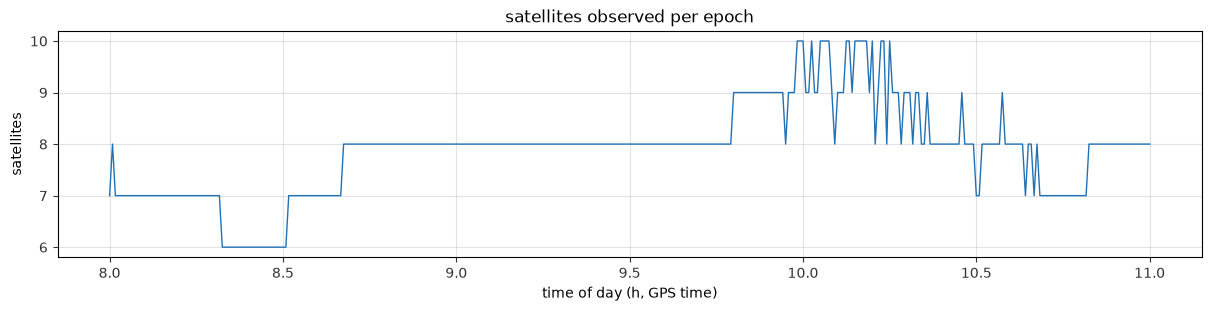

In [2]:
if src is not None:
    text = hatanaka.decompress(src.usud_obs).decode()
    header = text[: text.index("END OF HEADER")].splitlines()
    print("\n".join(header[:18]))
    print(read_rinex_header(src.usud_obs))
else:
    e = epochs[0]
    print(f"first epoch: week {e.week}, tow {e.tow:.1f} s")
    display(pd.DataFrame([vars(o) for o in e.obs]))

fig, ax = figure(figsize=(12, 3))
ax.plot(hours, [len(e.obs) for e in epochs], color=LINES[0], linewidth=1)
ax.set_xlabel("time of day (h, GPS time)")
ax.set_ylabel("satellites")
ax.set_title("satellites observed per epoch")
plt.show()

## 2. Satellite orbits

The ephemeris describes each satellite's orbit as a perturbed Kepler ellipse, good for a
few hours around its reference time. Evaluating it at the transmit time gives the
satellite's position, and the sky plot shows where each one was seen from the station.

On the station data the second figure checks the broadcast orbit against the IGS final
orbit (the SP3 file): the difference is at the metre level in the radial, along-track and
cross-track directions. The SP3 position refers to the satellite's centre of mass rather
than its antenna, and its clock excludes the relativistic term, so some offset is expected.

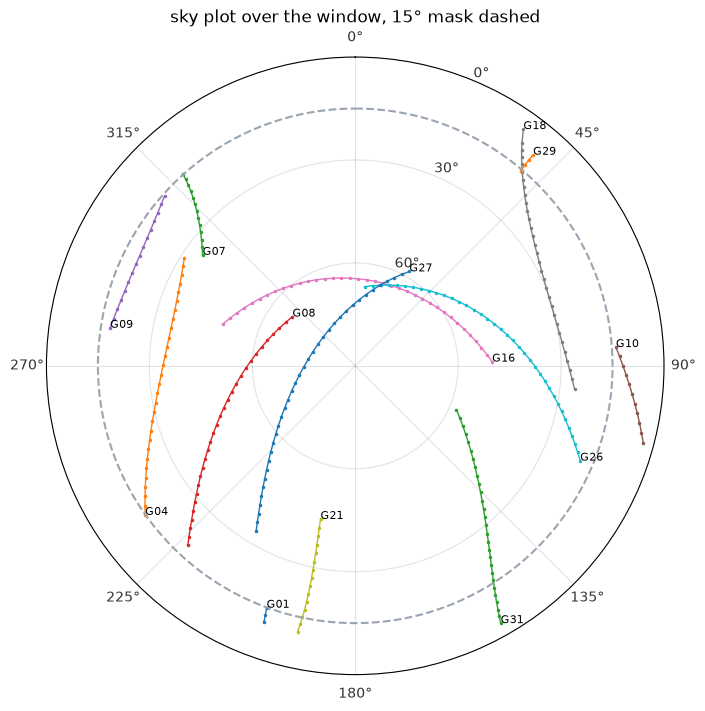

In [3]:
sky = {}
for e in epochs[::10]:
    for o in e.obs:
        eph = select_ephemeris(ephs, o.prn, e.tow)
        if eph is None:
            continue
        s = satellite_state(eph, e.tow - 0.07)
        az, el = azimuth_elevation(truth, s.position)
        sky.setdefault(o.prn, []).append((np.degrees(az), np.degrees(el)))

fig, ax = figure(figsize=(7, 7), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
for prn, points in sorted(sky.items()):
    pts = np.array(points)
    ax.plot(np.radians(pts[:, 0]), 90 - pts[:, 1], ".-", markersize=3, linewidth=1)
    ax.annotate(f"G{prn:02d}", (np.radians(pts[-1, 0]), 90 - pts[-1, 1]), fontsize=8)
ax.plot(np.linspace(0, 2 * np.pi, 180), np.full(180, 75), "--", color=MUTED)
ax.set_rlim(0, 90)
ax.set_rticks([0, 30, 60, 90])
ax.set_yticklabels(["90°", "60°", "30°", "0°"])
ax.set_title("sky plot over the window, 15° mask dashed")
plt.show()

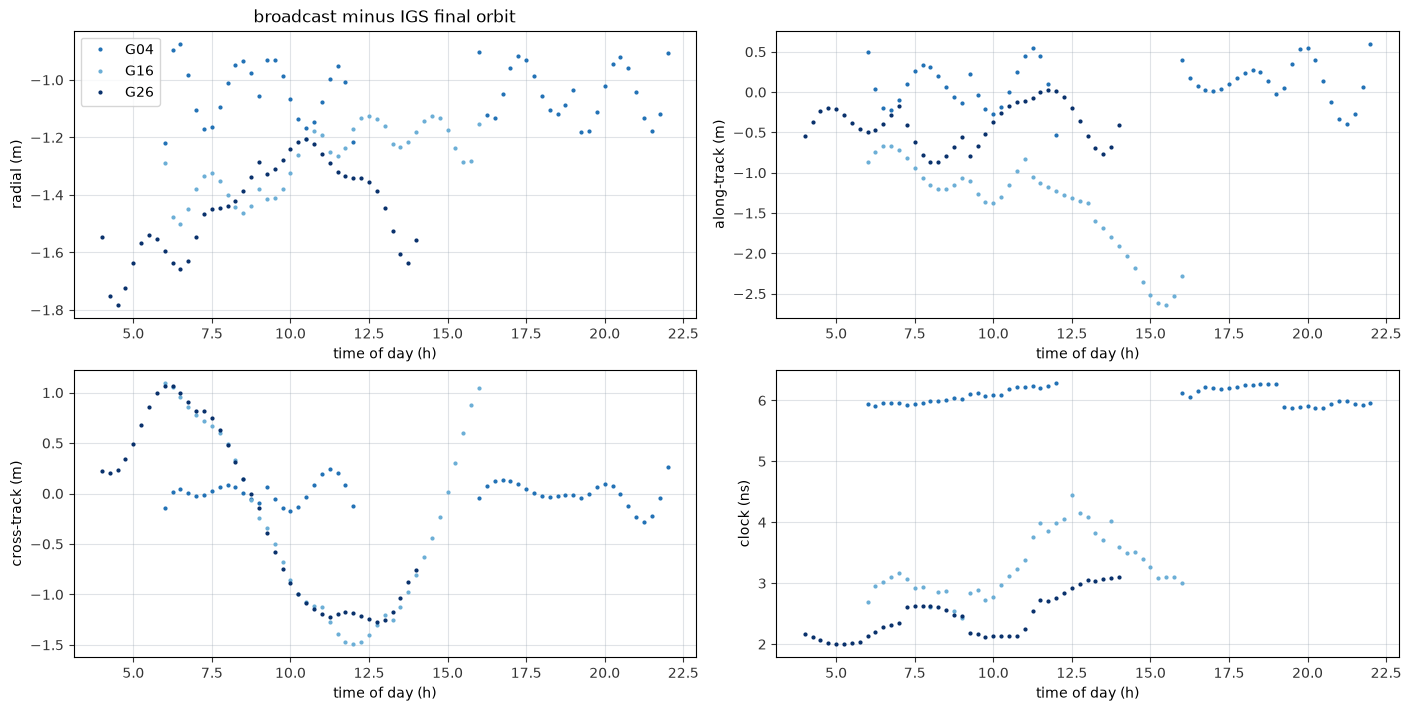

In [4]:
if src is None:
    print("synthetic data: no precise orbit to compare against")
else:
    import georinex

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        sp3 = georinex.load(src.sp3)
    fig, axes = figure(2, 2, figsize=(14, 7))
    for prn, color in zip((4, 16, 26), LINES):
        rows = []
        for t in sp3.time.values:
            tow = float(((t - np.datetime64(GPS_EPOCH)) / np.timedelta64(1, "s")) % 604800)
            eph = select_ephemeris(ephs, prn, tow)
            p = sp3.sel(sv=f"G{prn:02d}", time=t)
            pos, clk = p["position"].values * 1e3, float(p["clock"].values) * 1e-6
            if eph is None or not np.all(np.isfinite(pos)) or abs(clk) > 0.9:
                continue
            s = satellite_state(eph, tow)
            radial = s.position / np.linalg.norm(s.position)
            cross = np.cross(s.position, s.velocity)
            cross /= np.linalg.norm(cross)
            along = np.cross(cross, radial)
            d = s.position - pos
            rows.append((tow / 3600, d @ radial, d @ along, d @ cross,
                         (satellite_clock(eph, tow) - clk) * 1e9))
        rows = np.array(rows)
        for ax, j, name in zip(axes.flat, (1, 2, 3, 4), ("radial (m)", "along-track (m)", "cross-track (m)", "clock (ns)")):
            ax.plot(rows[:, 0], rows[:, j], ".", markersize=4, color=color, label=f"G{prn:02d}")
            ax.set_ylabel(name)
            ax.set_xlabel("time of day (h)")
    axes[0, 0].set_title("broadcast minus IGS final orbit")
    axes[0, 0].legend()
    plt.show()

## 3. The atmosphere

Two delays stretch each pseudorange. The ionosphere's is modelled with the Klobuchar
coefficients broadcast in the navigation message (RTKLIB's default set when the file has
none); the troposphere's with the Saastamoinen model from the station's height. Both grow
towards the horizon, which is why satellites below 15° of elevation are left out.

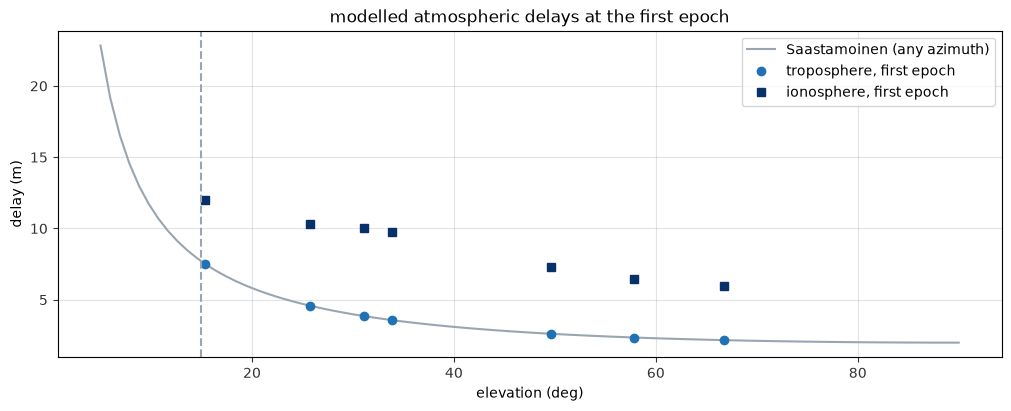

In [5]:
e = epochs[0]
lat, lon, h = geodetic(truth)
rows = []
for o in e.obs:
    eph = select_ephemeris(ephs, o.prn, e.tow)
    if eph is None:
        continue
    s = satellite_state(eph, e.tow - 0.07)
    az, el = azimuth_elevation(truth, s.position)
    rows.append((o.prn, np.degrees(el), klobuchar(iono or IONO_DEFAULT, lat, lon, az, el, e.tow), saastamoinen(lat, h, el)))
rows = np.array(rows)
els = np.radians(np.linspace(5, 90, 90))

fig, ax = figure(figsize=(10, 4))
ax.plot(np.degrees(els), [saastamoinen(lat, h, el) for el in els], color=MUTED, label="Saastamoinen (any azimuth)")
ax.plot(rows[:, 1], rows[:, 3], "o", color=LINES[0], label="troposphere, first epoch")
ax.plot(rows[:, 1], rows[:, 2], "s", color=LINES[2], label="ionosphere, first epoch")
for prn, el, _, _ in rows:
    ax.annotate(f"G{int(prn):02d}", (el, 0.3), fontsize=8, ha="center")
ax.axvline(15, color=MUTED, linestyle="--")
ax.set_xlabel("elevation (deg)")
ax.set_ylabel("delay (m)")
ax.set_title("modelled atmospheric delays at the first epoch")
ax.legend()
plt.show()

## 4. The solution

Each epoch is solved on its own: the satellite positions and clocks at their transmit
times, the modelled delays removed, then four or more unknowns (position and receiver
clock) from the pseudoranges by weighted least squares, iterated to convergence. The
figures show the position error about the station's known coordinates in east, north and
up, the geometry (GDOP and satellite count), the receiver clock and the residuals that are
left. The vertical error is the largest, as it always is with satellites only above the
horizon, and what the broadcast ionosphere model gets wrong lands mostly there: on this
window the solution sits several metres low. The station's receiver steers its clock to
GPS time, so its bias stays within microseconds; the synthetic receiver's drifts linearly.

360 of 361 epochs solved; 3-D error mean 8.11 m, 95 % 9.81 m, max 12.33 m; mean offset E +0.54 N +0.88 U -8.01 m


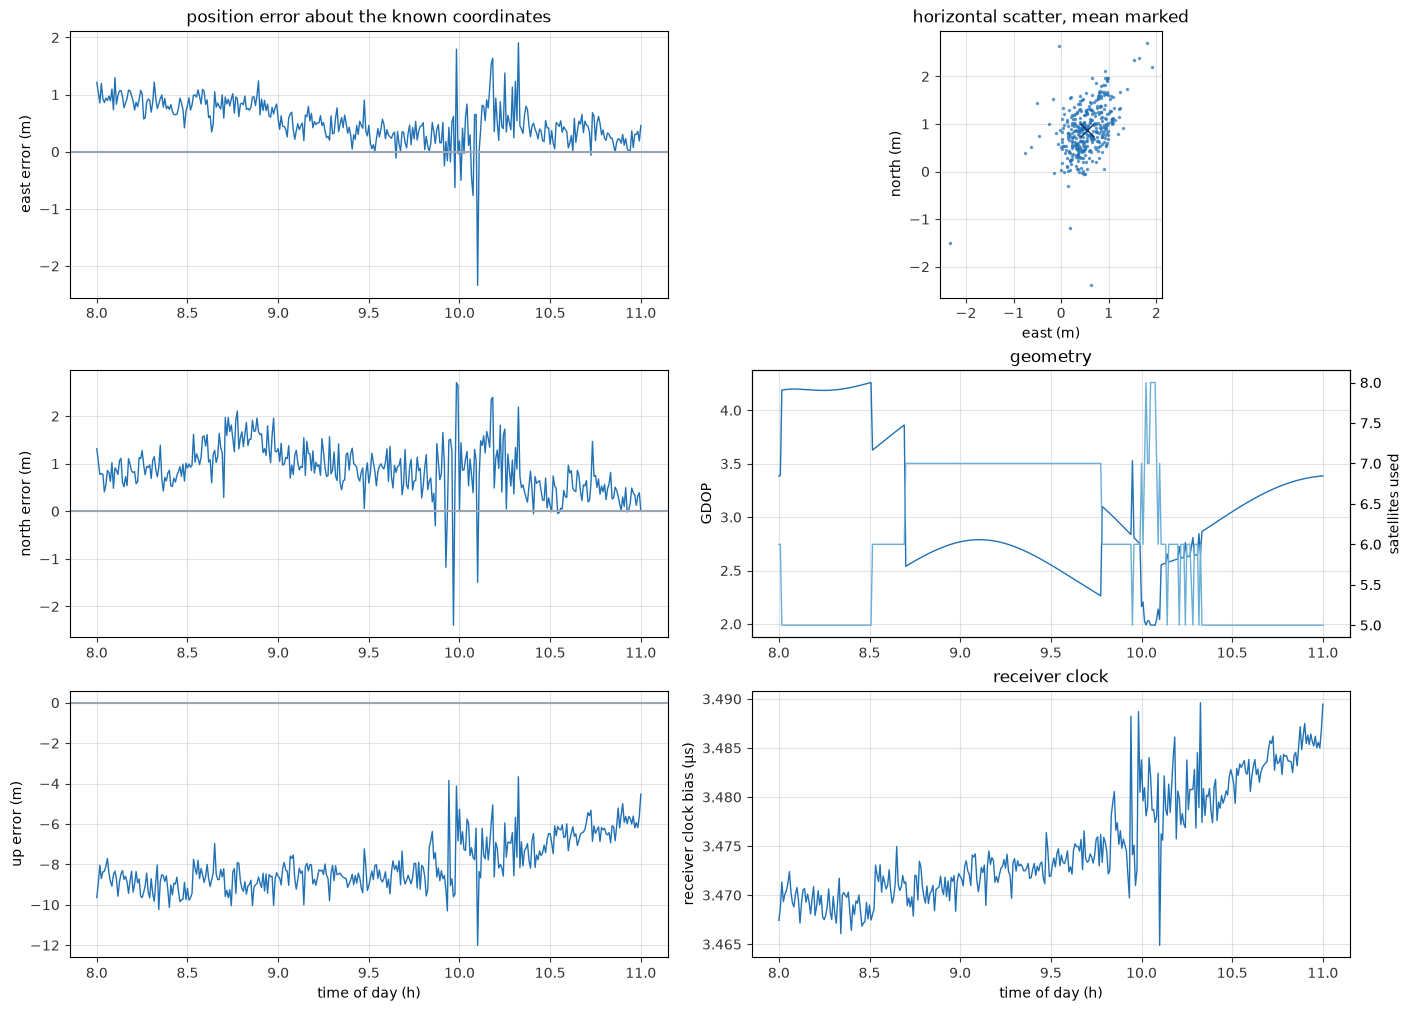

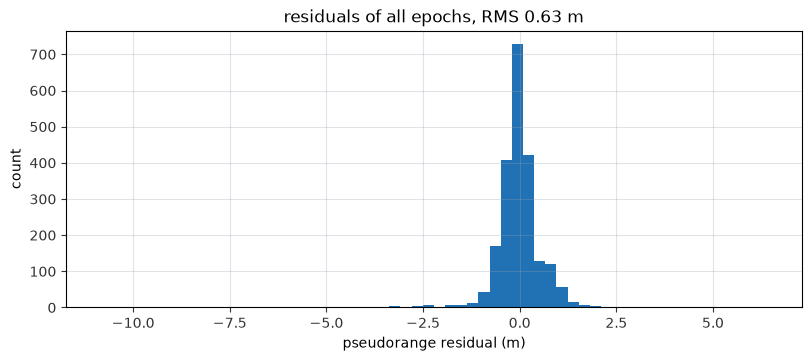

In [6]:
sols = solve(epochs, ephs, iono, 15.0)
err = enu(np.array([s.position for s in sols]), truth)
t = np.array([s.tow / 3600.0 for s in sols])
d3 = np.linalg.norm(err, axis=1)
print(f"{len(sols)} of {len(epochs)} epochs solved; 3-D error mean {d3.mean():.2f} m, "
      f"95 % {np.percentile(d3, 95):.2f} m, max {d3.max():.2f} m; "
      f"mean offset E {err[:, 0].mean():+.2f} N {err[:, 1].mean():+.2f} U {err[:, 2].mean():+.2f} m")

fig, axes = figure(3, 2, figsize=(14, 10))
for ax, j, name in zip(axes[:, 0], range(3), ("east", "north", "up")):
    ax.plot(t, err[:, j], color=LINES[0], linewidth=1)
    ax.axhline(0, color=MUTED)
    ax.set_ylabel(f"{name} error (m)")
axes[2, 0].set_xlabel("time of day (h)")
axes[0, 0].set_title("position error about the known coordinates")
ax = axes[0, 1]
ax.plot(err[:, 0], err[:, 1], ".", color=LINES[0], markersize=3, alpha=0.6)
ax.plot(err[:, 0].mean(), err[:, 1].mean(), "x", color=LINES[2], markersize=10)
ax.set_aspect("equal")
ax.set_xlabel("east (m)")
ax.set_ylabel("north (m)")
ax.set_title("horizontal scatter, mean marked")
ax = axes[1, 1]
ax.plot(t, [s.gdop for s in sols], color=LINES[0], linewidth=1, label="GDOP")
ax.set_ylabel("GDOP")
ax2 = ax.twinx()
ax2.plot(t, [len(s.prns) for s in sols], color=LINES[1], linewidth=1, label="satellites")
ax2.set_ylabel("satellites used")
ax.set_title("geometry")
ax = axes[2, 1]
ax.plot(t, [s.clock_bias * 1e6 for s in sols], color=LINES[0], linewidth=1)
ax.set_xlabel("time of day (h)")
ax.set_ylabel("receiver clock bias (µs)")
ax.set_title("receiver clock")
plt.show()

fig, ax = figure(figsize=(8, 3.5))
res = np.concatenate([s.residuals for s in sols])
ax.hist(res, bins=60, color=BAR_DETECTED)
ax.set_xlabel("pseudorange residual (m)")
ax.set_ylabel("count")
ax.set_title(f"residuals of all epochs, RMS {np.sqrt(np.mean(res**2)):.2f} m")
plt.show()

## 5. Against the reference

RTKLIB's `rnx2rtkp` in single-point mode with the same models (GPS only, 15° mask,
broadcast Klobuchar, Saastamoinen) gives an independent solution of the same file. Its
east, north and up errors are overlaid on ours, and the per-epoch difference between the
two solvers is shown below: a fraction of a millimetre, except at an epoch that falls
exactly midway between two reference times of a satellite's ephemeris, where the two
solvers pick different records and the fix moves by a decimetre.

360 common epochs; RTKLIB minus pyrx: mean |E| 0.4 mm, |N| 0.1 mm, |U| 0.7 mm


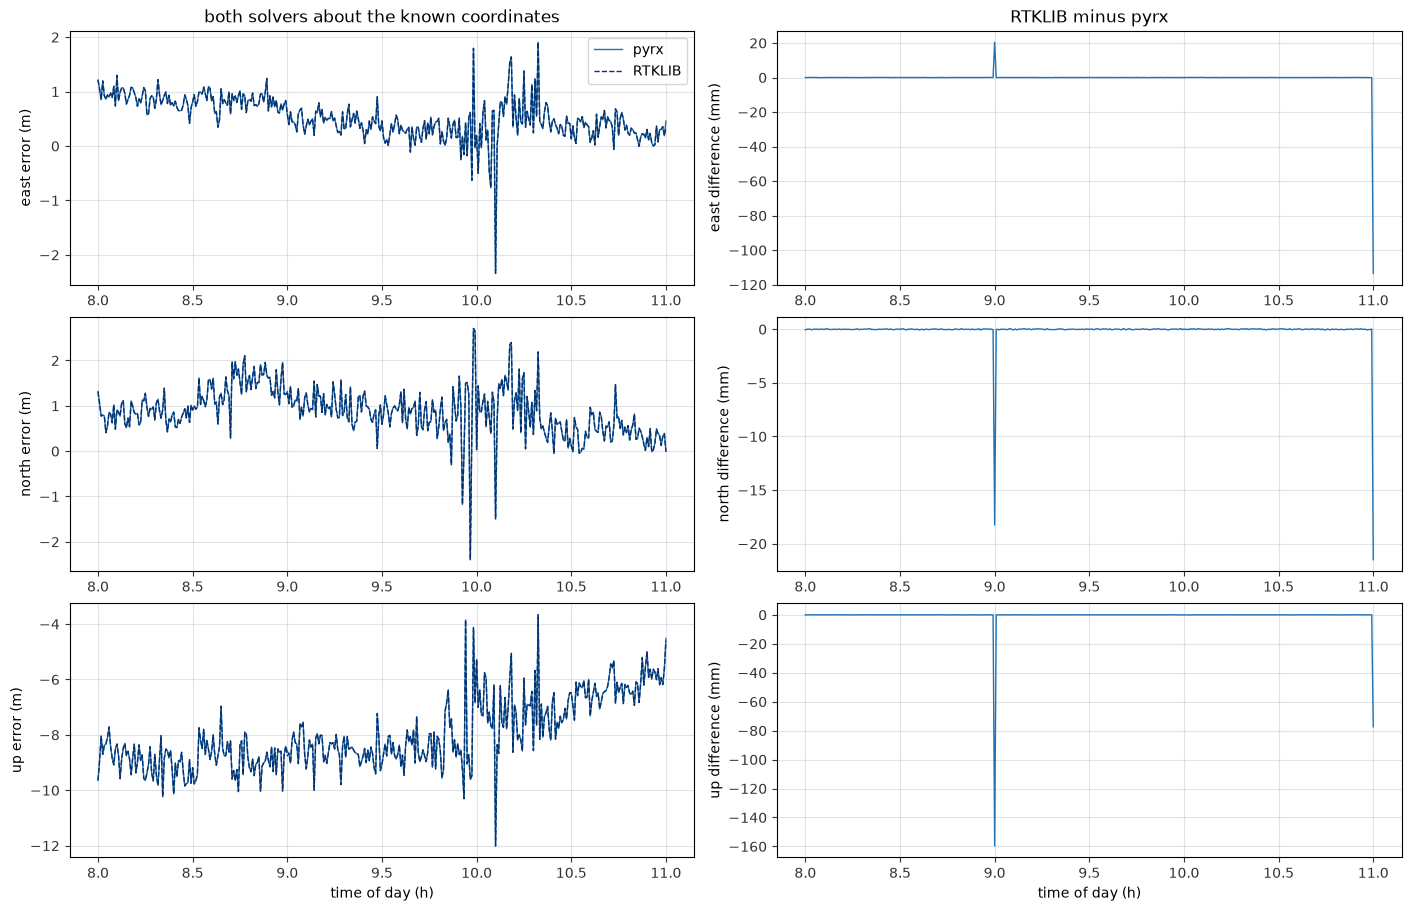

In [7]:
ref = None if src is None else rnx2rtkp_single(src.usud_obs, src.usud_nav, out, PVT_SPAN)
if ref is None:
    print("no reference solution" if src is not None else "synthetic data: no reference solution")
else:
    keys = [(s.week, round(s.tow, 1)) for s in sols]
    both = [(i, ref[k]) for i, k in enumerate(keys) if k in ref]
    idx = np.array([i for i, _ in both])
    ref_err = enu(np.array([xyz for _, xyz in both]), truth)
    diff = ref_err - err[idx]
    print(f"{len(both)} common epochs; RTKLIB minus pyrx: mean |E| {np.abs(diff[:, 0]).mean() * 1e3:.1f} mm, "
          f"|N| {np.abs(diff[:, 1]).mean() * 1e3:.1f} mm, |U| {np.abs(diff[:, 2]).mean() * 1e3:.1f} mm")
    fig, axes = figure(3, 2, figsize=(14, 9))
    for j, name in enumerate(("east", "north", "up")):
        ax = axes[j, 0]
        ax.plot(t, err[:, j], color=LINES[0], linewidth=1, label="pyrx")
        ax.plot(t[idx], ref_err[:, j], "--", color=LINES[2], linewidth=1, label="RTKLIB")
        ax.set_ylabel(f"{name} error (m)")
        ax = axes[j, 1]
        ax.plot(t[idx], diff[:, j] * 1e3, color=LINES[0], linewidth=1)
        ax.set_ylabel(f"{name} difference (mm)")
    axes[0, 0].legend()
    axes[0, 0].set_title("both solvers about the known coordinates")
    axes[0, 1].set_title("RTKLIB minus pyrx")
    axes[2, 0].set_xlabel("time of day (h)")
    axes[2, 1].set_xlabel("time of day (h)")
    plt.show()